# Binomial

Lecture 2 (16/11) - Distributions

## Exercise

Compute the distribution of Binomial variables with $n = 150$ and $p = 0.1,\ 0.3,\ 0.5,\ 0.7,\ 0.9$.

Plot them all together (overlay them). **Do not use any predefined method for the Binomial or factorial!**

Repeat for $n = 500$.

**Tricks**

1. *Binomial coefficient with* $\exp(\log)$:

   $$\binom{n}{k} = \frac{n!}{k!\,(n-k)!} = \frac{n\,(n-1)\,(n-2)\cdots 3\cdot 2\cdot 1}{k\,(k-1)\cdots 3\cdot 2\;\cdot\;(n-k)\,(n-k-1)\cdots 3\cdot 2} = \frac{n\,(n-1)\cdots(n-k+1)}{k\,(k-1)\cdots 3\cdot 2}$$

   The last form works numerically up to $k \approx 170$. Then

   $$\binom{n}{k} = \exp\!\Big[\ln\big(n(n-1)\cdots(n-k+1)\big) - \ln\big(k(k-1)\cdots 3\cdot 2\big)\Big] = \exp\!\Big[\sum_{i=n-k+1}^{n}\ln(i) - \sum_{i=2}^{k}\ln(i)\Big]$$

2. *Bernoulli term with* $\exp(\log)$, to solve the situation with small $p$ and large $(1-p)$:

   $$p^k (1-p)^{n-k} = \exp\!\Big[\ln\big(p^k(1-p)^{n-k}\big)\Big] = \exp\!\big[k\ln(p) + (n-k)\ln(1-p)\big]$$

## Solution

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom

### Binomial Distribution

In [19]:
def binom_naive(n, p):
    pmf = np.empty(n + 1)
    for k in range(n + 1):
        num = 1.0
        for i in range(n - k + 1, n + 1):   # n(n-1)...(n-k+1)
            num *= i
        den = 1.0
        for i in range(2, k + 1):           # k!
            den *= i
        pmf[k] = num / den * p**k * (1 - p)**(n - k)
    return pmf

In [24]:
def binom_log(n, p):
    k = np.arange(n + 1)
    # ln(m!) = sum_{i=2}^{m} ln i, for m = 0..n
    #ln_fact = np.concatenate(([0.0], np.cumsum(np.log(np.arange(1, n + 1)))))
    ld = np.longdouble
    ln_fact = np.concatenate(([ld(0)], np.cumsum(np.log(np.arange(1, n + 1, dtype=ld)))))
    ln_coef = ln_fact[n] - ln_fact[k] - ln_fact[n - k]   # ln C(n,k)
    return np.exp(ln_coef + k * np.log(p) + (n - k) * np.log(1 - p))


### Plots

In [25]:
# Data
ps = np.array([0.1, 0.3, 0.5, 0.7, 0.9])
ns = np.array([150, 500])

/tmp/ipykernel_68285/1127063860.py:10: RuntimeWarning: invalid value encountered in scalar multiply
  pmf[k] = num / den * p**k * (1 - p)**(n - k)


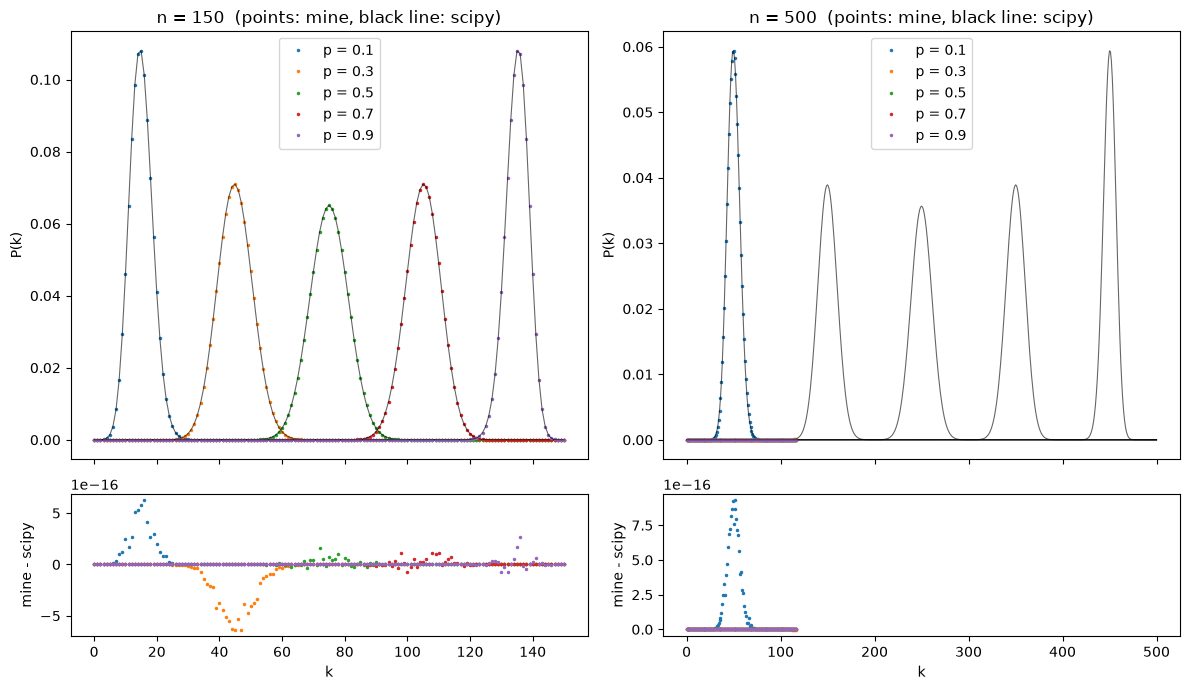

In [26]:
# Naive implementation of the binomial PMF
fig, axes = plt.subplots(2, len(ns), figsize=(12, 7), sharex="col",
                         gridspec_kw={"height_ratios": [3, 1]})

for j, n in enumerate(ns):
    k = np.arange(n + 1)
    ax_top, ax_res = axes[0, j], axes[1, j]
    for p in ps:
        mine = binom_naive(n, p)
        true = binom.pmf(k, n, p)
        line, = ax_top.plot(k, mine, ".", ms=3, label=f"p = {p}")
        ax_top.plot(k, true, "-", lw=0.8, color="k", alpha=0.6)
        ax_res.plot(k, mine - true, ".", ms=3, color=line.get_color())
    ax_top.set_title(f"n = {n}  (points: mine, black line: scipy)")
    ax_top.set_ylabel("P(k)")
    ax_top.legend()
    ax_res.set_xlabel("k")
    ax_res.set_ylabel("mine - scipy")

fig.tight_layout()
plt.show()


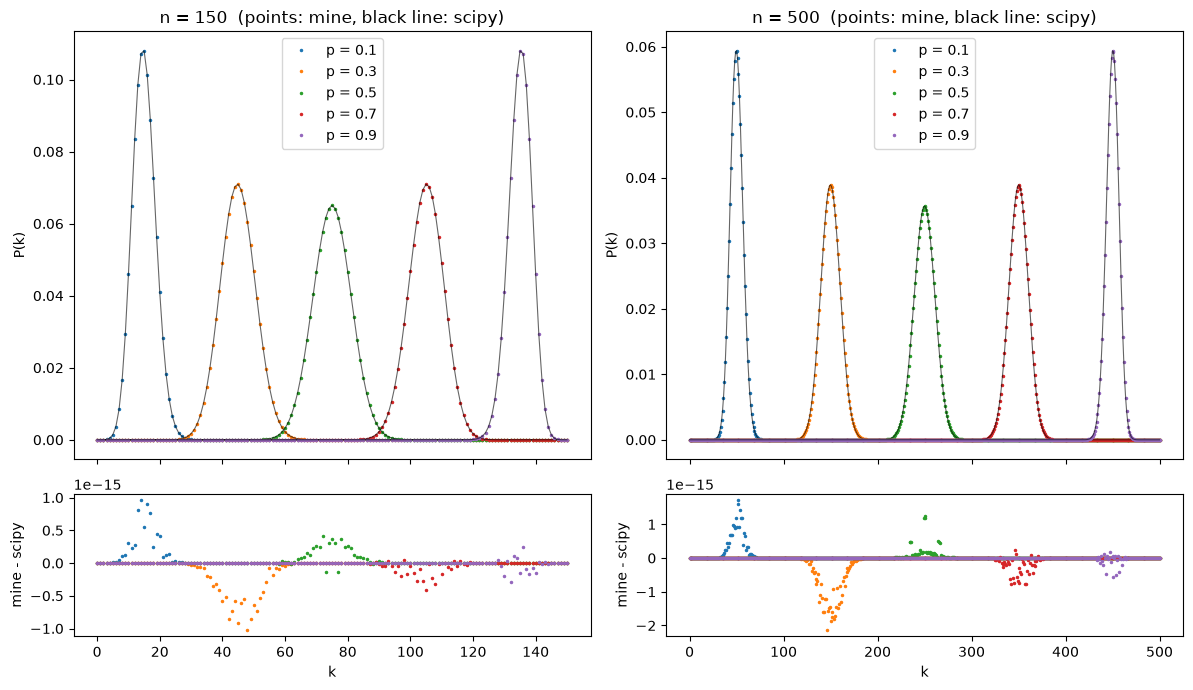

In [27]:
# Binomial PMF using log factorials
fig, axes = plt.subplots(2, len(ns), figsize=(12, 7), sharex="col",
                         gridspec_kw={"height_ratios": [3, 1]})

for j, n in enumerate(ns):
    k = np.arange(n + 1)
    ax_top, ax_res = axes[0, j], axes[1, j]
    for p in ps:
        mine = binom_log(n, p)
        true = binom.pmf(k, n, p)
        line, = ax_top.plot(k, mine, ".", ms=3, label=f"p = {p}")
        ax_top.plot(k, true, "-", lw=0.8, color="k", alpha=0.6)
        ax_res.plot(k, mine - true, ".", ms=3, color=line.get_color())
    ax_top.set_title(f"n = {n}  (points: mine, black line: scipy)")
    ax_top.set_ylabel("P(k)")
    ax_top.legend()
    ax_res.set_xlabel("k")
    ax_res.set_ylabel("mine - scipy")

fig.tight_layout()
plt.show()


## Conclusions

- **Shape.** Each distribution peaks at $k\approx np$ with width
  $\sigma=\sqrt{np(1-p)}$. The curves for $p$ and $1-p$ are mirror images
  around $n/2$, since $P(k;n,p)=P(n-k;n,1-p)$. The width is largest for
  $p=0.5$, where the peak is lowest (the area is fixed to 1).
- **Dependence on $n$.** $\sigma$ grows only as $\sqrt{n}$ while the mean grows
  as $n$, so the relative width $\sigma/\mu\propto 1/\sqrt{n}$ shrinks.
  The skewness $(1-2p)/\sigma$ also decreases, and the distributions get
  closer to a Gaussian (central limit theorem).
- **Numerics.** The direct computation is accurate but overflows for large
  $n$; the log version is slightly less precise ($10^{-14}$–$10^{-13}$ instead
  of $10^{-16}$) but robust for any $n$. The loss of precision is negligible
  for any practical use.
